In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("HR Analytics Project Started!")

HR Analytics Project Started!


In [2]:


df = pd.read_csv("../data/raw/hr_employee_attrition.csv")

df.head()

,EmployeeID,Age,Gender,Department,JobRole,Education,MonthlyIncome,YearsAtCompany,YearsInRole,JobSatisfaction,WorkLifeBalance,PerformanceRating,OverTime,TrainingHours,BusinessTravel,PromotionLast5Years,DistanceFromHome,HireDate,Attrition
0,EMP0001,30,Female,IT,IT Support,Bachelor's,8457.0,3,1,2.0,2,3,Yes,53.0,Frequently,No,7,4/8/2019,No
1,EMP0002,35,Male,Research & Development,Lab Technician,Bachelor's,9243.0,16,6,3.0,3,4,No,17.0,Frequently,No,10,3/11/2013,No
2,EMP0003,37,Female,IT,IT Support,Bachelor's,5999.0,1,0,3.0,2,3,No,26.0,Non-Travel,No,9,9/22/2022,No
3,EMP0004,27,Female,Human Resources,HR Manager,Bachelor's,4996.0,2,1,2.0,1,3,No,38.0,Rarely,No,21,1/13/2013,No
4,EMP0005,41,Male,Sales,Sales Representative,Bachelor's,3482.0,3,2,4.0,1,3,No,29.0,Rarely,Yes,17,11/21/2012,No


In [3]:
df.shape

(600, 19)

In [4]:
df.columns

Index(['EmployeeID', 'Age', 'Gender', 'Department', 'JobRole', 'Education',
       'MonthlyIncome', 'YearsAtCompany', 'YearsInRole', 'JobSatisfaction',
       'WorkLifeBalance', 'PerformanceRating', 'OverTime', 'TrainingHours',
       'BusinessTravel', 'PromotionLast5Years', 'DistanceFromHome', 'HireDate',
       'Attrition'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   EmployeeID           600 non-null    str    
 1   Age                  600 non-null    int64  
 2   Gender               600 non-null    str    
 3   Department           600 non-null    str    
 4   JobRole              600 non-null    str    
 5   Education            600 non-null    str    
 6   MonthlyIncome        595 non-null    float64
 7   YearsAtCompany       600 non-null    int64  
 8   YearsInRole          600 non-null    int64  
 9   JobSatisfaction      597 non-null    float64
 10  WorkLifeBalance      600 non-null    int64  
 11  PerformanceRating    600 non-null    int64  
 12  OverTime             600 non-null    str    
 13  TrainingHours        596 non-null    float64
 14  BusinessTravel       598 non-null    str    
 15  PromotionLast5Years  600 non-null    str    
 16  D

In [6]:
df.isnull().sum()

EmployeeID             0
Age                    0
Gender                 0
Department             0
JobRole                0
Education              0
MonthlyIncome          5
YearsAtCompany         0
YearsInRole            0
JobSatisfaction        3
WorkLifeBalance        0
PerformanceRating      0
OverTime               0
TrainingHours          4
BusinessTravel         2
PromotionLast5Years    0
DistanceFromHome       0
HireDate               0
Attrition              0
dtype: int64

In [7]:
df_clean = df.copy()

print("Original rows:", df.shape[0])
print("Working copy rows:", df_clean.shape[0])

Original rows: 600
Working copy rows: 600


=============Check Duplicate rows==================

In [8]:
print('Duplicated_rows',df_clean.duplicated().sum())

Duplicated_rows 0


==============check duplicate  employes id================ 

In [9]:
print('Employes id rows',df_clean['EmployeeID'].duplicated().sum())

Employes id rows 0


===========================Check missing values================

In [10]:
missing = df_clean.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

MonthlyIncome      5
TrainingHours      4
JobSatisfaction    3
BusinessTravel     2
dtype: int64

In [11]:
df_clean.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
EmployeeID,600,600,EMP0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,600.0,NaN,NaN,NaN,35.225,7.713854,21.0,30.0,35.0,40.0,57.0
Gender,600,3,Male,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,600,5,Research & Development,193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
JobRole,600,15,Lab Technician,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,600,4,Bachelor's,292,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthlyIncome,595.0,NaN,NaN,NaN,5962.6,1328.910956,2167.0,5038.0,5988.0,6869.5,9611.0
YearsAtCompany,600.0,NaN,NaN,NaN,4.973333,3.362757,0.0,3.0,4.0,7.0,22.0
YearsInRole,600.0,NaN,NaN,NaN,3.23,2.524094,0.0,1.0,3.0,4.0,18.0
JobSatisfaction,597.0,NaN,NaN,NaN,2.740369,0.980307,1.0,2.0,3.0,4.0,4.0


============================Missing values report=====================================

In [12]:
missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_report[missing_report["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage
MonthlyIncome,5,0.83
JobSatisfaction,3,0.50
TrainingHours,4,0.67
BusinessTravel,2,0.33


In [13]:
df_clean.isnull().sum()

EmployeeID             0
Age                    0
Gender                 0
Department             0
JobRole                0
Education              0
MonthlyIncome          5
YearsAtCompany         0
YearsInRole            0
JobSatisfaction        3
WorkLifeBalance        0
PerformanceRating      0
OverTime               0
TrainingHours          4
BusinessTravel         2
PromotionLast5Years    0
DistanceFromHome       0
HireDate               0
Attrition              0
dtype: int64

In [14]:
df_clean['MonthlyIncome'].isnull().sum()

np.int64(5)

In [15]:
df_clean['MonthlyIncome'] = df_clean['MonthlyIncome'].fillna(df_clean["MonthlyIncome"].median()
                                                            )

In [16]:
df_clean["MonthlyIncome"].isnull().sum()

np.int64(0)

In [17]:
df_clean["TrainingHours"] = df_clean["TrainingHours"].fillna(
    df_clean["TrainingHours"].median()
)

In [18]:
df_clean["TrainingHours"].isnull().sum()

np.int64(0)

In [19]:
df_clean["JobSatisfaction"] = df_clean["JobSatisfaction"].fillna(df_clean["JobSatisfaction"].mode()[0])

In [20]:
df_clean['JobSatisfaction'].isnull().sum()

np.int64(0)

In [21]:
df_clean["BusinessTravel"] = df_clean["BusinessTravel"].fillna(
    df_clean["BusinessTravel"].mode()[0]
)

In [22]:
df_clean["BusinessTravel"].isnull().sum()

np.int64(0)

In [23]:
df_clean.isnull().sum()

EmployeeID             0
Age                    0
Gender                 0
Department             0
JobRole                0
Education              0
MonthlyIncome          0
YearsAtCompany         0
YearsInRole            0
JobSatisfaction        0
WorkLifeBalance        0
PerformanceRating      0
OverTime               0
TrainingHours          0
BusinessTravel         0
PromotionLast5Years    0
DistanceFromHome       0
HireDate               0
Attrition              0
dtype: int64

=================Check data Type================

In [24]:
df_clean.dtypes

EmployeeID                 str
Age                      int64
Gender                     str
Department                 str
JobRole                    str
Education                  str
MonthlyIncome          float64
YearsAtCompany           int64
YearsInRole              int64
JobSatisfaction        float64
WorkLifeBalance          int64
PerformanceRating        int64
OverTime                   str
TrainingHours          float64
BusinessTravel             str
PromotionLast5Years        str
DistanceFromHome         int64
HireDate                   str
Attrition                  str
dtype: object

In [25]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,600.0,35.225000,7.713854,21.0,30.0,35.0,40.0,57.0
MonthlyIncome,600.0,5962.811667,1323.354978,2167.0,5047.0,5988.0,6855.0,9611.0
YearsAtCompany,600.0,4.973333,3.362757,0.0,3.0,4.0,7.0,22.0
YearsInRole,600.0,3.230000,2.524094,0.0,1.0,3.0,4.0,18.0
JobSatisfaction,600.0,2.741667,0.978021,1.0,2.0,3.0,4.0,4.0
WorkLifeBalance,600.0,2.796667,0.920181,1.0,2.0,3.0,3.0,4.0
PerformanceRating,600.0,2.805000,0.742447,1.0,2.0,3.0,3.0,4.0
TrainingHours,600.0,40.008333,17.536461,0.0,29.0,39.0,52.0,98.0
DistanceFromHome,600.0,8.528333,5.799591,1.0,4.0,7.0,12.0,30.0


In [26]:
print("Attrition values:")
print(df_clean["Attrition"].value_counts())

print("\nOverTime values:")
print(df_clean["OverTime"].value_counts())

print("\nDepartment values:")
print(df_clean["Department"].value_counts())

Attrition values:
Attrition
No     501
Yes     99
Name: count, dtype: int64

OverTime values:
OverTime
No     404
Yes    196
Name: count, dtype: int64

Department values:
Department
Research & Development    193
Sales                     168
IT                        111
Human Resources            64
Finance                    64
Name: count, dtype: int64


In [27]:
total_employees = len(df_clean)

employees_left = (df_clean["Attrition"] == "Yes").sum()

attrition_rate = (employees_left / total_employees) * 100

print("Total Employees:", total_employees)
print("Employees Who Left:", employees_left)
print("Attrition Rate:", round(attrition_rate, 2), "%")

Total Employees: 600
Employees Who Left: 99
Attrition Rate: 16.5 %


In [28]:
pd.crosstab(
    df_clean["OverTime"],
    df_clean["Attrition"],
    normalize="index"
).mul(100).round(2)

Attrition,No,Yes
OverTime,,
No,88.12,11.88
Yes,73.98,26.02


In [29]:
pd.crosstab(
    df_clean["Department"],
    df_clean["Attrition"]
)

Attrition,No,Yes
Department,,
Finance,57,7
Human Resources,49,15
IT,87,24
Research & Development,159,34
Sales,149,19


In [30]:
dept_attrition = (
    df_clean.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

dept_attrition

Department
Human Resources           23.44
IT                        21.62
Research & Development    17.62
Sales                     11.31
Finance                   10.94
Name: Attrition, dtype: float64

=====================Visualization==================

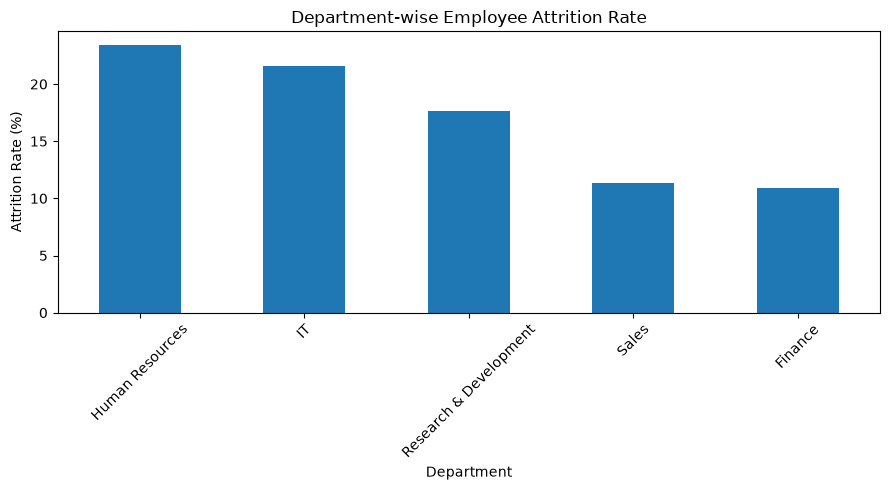

In [31]:
dept_attrition.plot(
    kind="bar",
    figsize=(9, 5),
    title="Department-wise Employee Attrition Rate"
)

plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

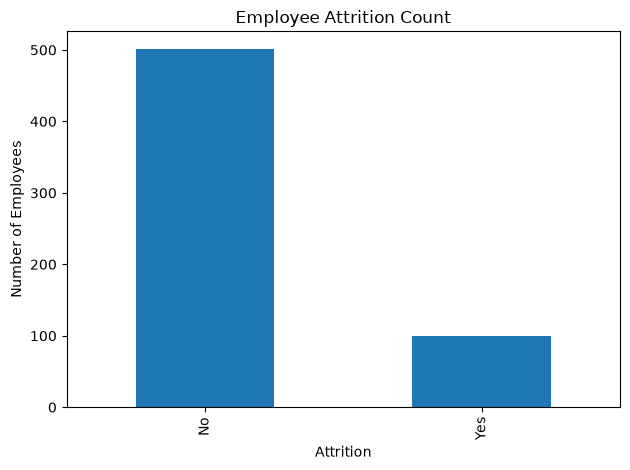

In [32]:
df_clean["Attrition"].value_counts().plot(
    kind="bar",
    title="Employee Attrition Count"
)

plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

In [33]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

df_clean[["Age", "AgeGroup"]].head(10)

,Age,AgeGroup
0,30,26-35
1,35,26-35
2,37,36-45
3,27,26-35
4,41,36-45
5,36,36-45
6,21,18-25
7,21,18-25
8,35,26-35
9,33,26-35


In [34]:
age_attrition = (
    df_clean.groupby("AgeGroup", observed=False)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

age_attrition

AgeGroup
18-25    21.43
26-35    16.87
36-45    15.49
46-55    13.56
56+       0.00
Name: Attrition, dtype: float64

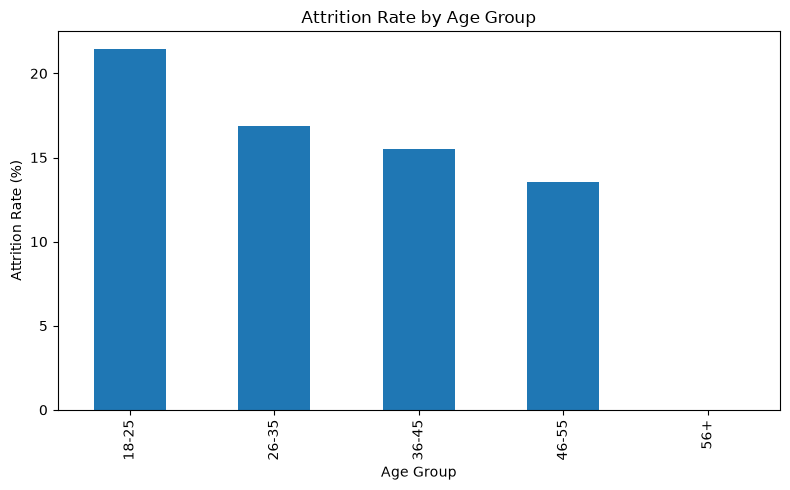

In [35]:
age_attrition.plot(
    kind="bar",
    figsize=(8, 5),
    title="Attrition Rate by Age Group"
)

plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

===================Salary groups=============

In [36]:

df_clean["IncomeGroup"] = pd.cut(
    df_clean["MonthlyIncome"],
    bins=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

df_clean[["MonthlyIncome", "IncomeGroup"]].head(10)


,MonthlyIncome,IncomeGroup
0,8457.0,High
1,9243.0,High
2,5999.0,Medium-High
3,4996.0,Medium-Low
4,3482.0,Low
5,4893.0,Medium-Low
6,7579.0,Medium-High
7,4617.0,Medium-Low
8,4346.0,Medium-Low
9,5401.0,Medium-Low


In [37]:
income_attrition = (
    df_clean.groupby("IncomeGroup", observed=False)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

income_attrition

IncomeGroup
Low            23.81
Medium-Low     12.76
Medium-High    16.98
High           26.00
Name: Attrition, dtype: float64

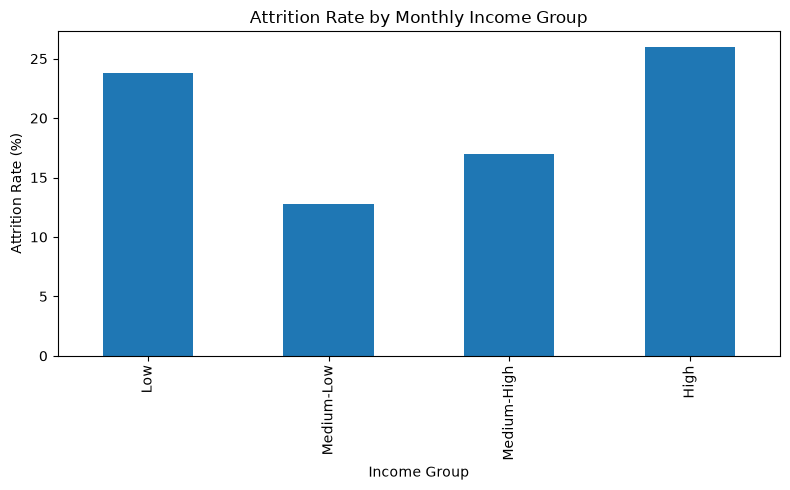

In [38]:
income_attrition.plot(
    kind="bar",
    figsize=(8, 5),
    title="Attrition Rate by Monthly Income Group"
)

plt.xlabel("Income Group")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

======================Job Satisfaction comparison=================

In [39]:
pd.crosstab(
    df_clean["JobSatisfaction"],
    df_clean["Attrition"]
)

Attrition,No,Yes
JobSatisfaction,,
1.0,58,20
2.0,125,25
3.0,191,30
4.0,127,24


In [40]:
satisfaction_attrition = (
    df_clean.groupby("JobSatisfaction")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

satisfaction_attrition

JobSatisfaction
1.0    25.64
2.0    16.67
3.0    13.57
4.0    15.89
Name: Attrition, dtype: float64

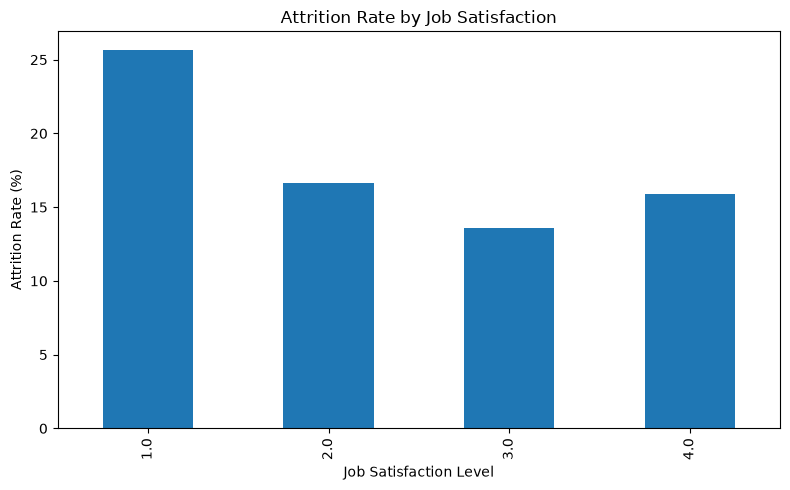

In [41]:
satisfaction_attrition.plot(
    kind="bar",
    figsize=(8, 5),
    title="Attrition Rate by Job Satisfaction"
)

plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

==============Attrition ke important factors summary======================

In [42]:
print("HR ANALYTICS - KEY METRICS")
print("--------------------------")

print("Total Employees:", len(df_clean))

print(
    "Employees Left:",
    (df_clean["Attrition"] == "Yes").sum()
)

print(
    "Overall Attrition Rate:",
    round((df_clean["Attrition"] == "Yes").mean() * 100, 2),
    "%"
)

print(
    "Employees Working Overtime:",
    (df_clean["OverTime"] == "Yes").sum()
)

print(
    "Highest Department Attrition Rate:",
    dept_attrition.idxmax(),
    "-",
    dept_attrition.max(),
    "%"
)

print(
    "Highest Age Group Attrition Rate:",
    age_attrition.idxmax(),
    "-",
    age_attrition.max(),
    "%"
)

print(
    "Highest Income Group Attrition Rate:",
    income_attrition.idxmax(),
    "-",
    income_attrition.max(),
    "%"
)

HR ANALYTICS - KEY METRICS
--------------------------
Total Employees: 600
Employees Left: 99
Overall Attrition Rate: 16.5 %
Employees Working Overtime: 196
Highest Department Attrition Rate: Human Resources - 23.44 %
Highest Age Group Attrition Rate: 18-25 - 21.43 %
Highest Income Group Attrition Rate: High - 26.0 %


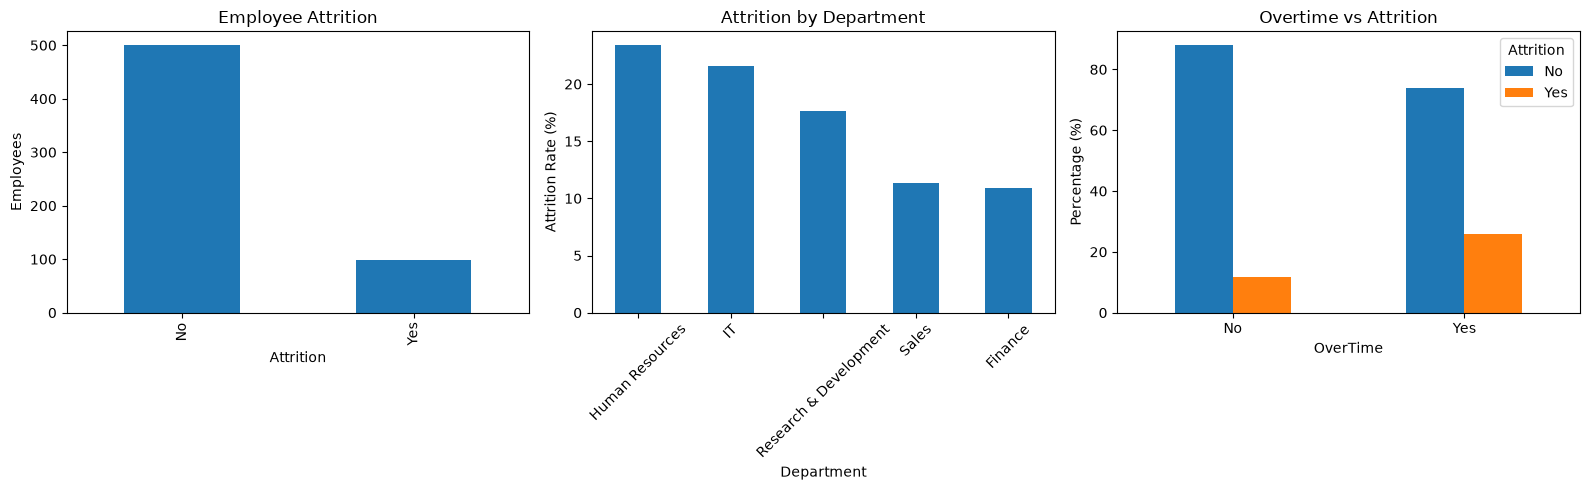

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Chart 1: Attrition count
df_clean["Attrition"].value_counts().plot(
    kind="bar", ax=axes[0], title="Employee Attrition"
)
axes[0].set_xlabel("Attrition")
axes[0].set_ylabel("Employees")

# Chart 2: Department-wise attrition rate
dept_attrition.plot(
    kind="bar", ax=axes[1], title="Attrition by Department"
)
axes[1].set_xlabel("Department")
axes[1].set_ylabel("Attrition Rate (%)")
axes[1].tick_params(axis="x", rotation=45)

# Chart 3: Overtime vs Attrition
pd.crosstab(
    df_clean["OverTime"],
    df_clean["Attrition"],
    normalize="index"
).mul(100).plot(
    kind="bar", ax=axes[2], title="Overtime vs Attrition"
)
axes[2].set_xlabel("OverTime")
axes[2].set_ylabel("Percentage (%)")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [44]:
report = pd.DataFrame({
    "Metric": [
        "Total Employees",
        "Employees Left",
        "Attrition Rate (%)",
        "Employees Working Overtime"
    ],
    "Value": [
        len(df_clean),
        (df_clean["Attrition"] == "Yes").sum(),
        round((df_clean["Attrition"] == "Yes").mean() * 100, 2),
        (df_clean["OverTime"] == "Yes").sum()
    ]
})

report

,Metric,Value
0,Total Employees,600.0
1,Employees Left,99.0
2,Attrition Rate (%),16.5
3,Employees Working Overtime,196.0


In [45]:
report.to_csv("hr_analytics_summary.csv", index=False)

In [46]:
df.shape

(600, 19)

In [47]:
df.isnull().sum()

EmployeeID             0
Age                    0
Gender                 0
Department             0
JobRole                0
Education              0
MonthlyIncome          5
YearsAtCompany         0
YearsInRole            0
JobSatisfaction        3
WorkLifeBalance        0
PerformanceRating      0
OverTime               0
TrainingHours          4
BusinessTravel         2
PromotionLast5Years    0
DistanceFromHome       0
HireDate               0
Attrition              0
dtype: int64

In [48]:
print("Original Data:")
print(df.isnull().sum())

print("\nCleaned Data:")
print(df_clean.isnull().sum())

Original Data:
EmployeeID             0
Age                    0
Gender                 0
Department             0
JobRole                0
Education              0
MonthlyIncome          5
YearsAtCompany         0
YearsInRole            0
JobSatisfaction        3
WorkLifeBalance        0
PerformanceRating      0
OverTime               0
TrainingHours          4
BusinessTravel         2
PromotionLast5Years    0
DistanceFromHome       0
HireDate               0
Attrition              0
dtype: int64

Cleaned Data:
EmployeeID             0
Age                    0
Gender                 0
Department             0
JobRole                0
Education              0
MonthlyIncome          0
YearsAtCompany         0
YearsInRole            0
JobSatisfaction        0
WorkLifeBalance        0
PerformanceRating      0
OverTime               0
TrainingHours          0
BusinessTravel         0
PromotionLast5Years    0
DistanceFromHome       0
HireDate               0
Attrition              0
AgeGrou

In [49]:
df_clean.isnull().sum()

EmployeeID             0
Age                    0
Gender                 0
Department             0
JobRole                0
Education              0
MonthlyIncome          0
YearsAtCompany         0
YearsInRole            0
JobSatisfaction        0
WorkLifeBalance        0
PerformanceRating      0
OverTime               0
TrainingHours          0
BusinessTravel         0
PromotionLast5Years    0
DistanceFromHome       0
HireDate               0
Attrition              0
AgeGroup               0
IncomeGroup            0
dtype: int64

In [50]:
print("Dataset Shape:", df_clean.shape)

print("\nColumn Names:")
print(df_clean.columns.tolist())

Dataset Shape: (600, 21)

Column Names:
['EmployeeID', 'Age', 'Gender', 'Department', 'JobRole', 'Education', 'MonthlyIncome', 'YearsAtCompany', 'YearsInRole', 'JobSatisfaction', 'WorkLifeBalance', 'PerformanceRating', 'OverTime', 'TrainingHours', 'BusinessTravel', 'PromotionLast5Years', 'DistanceFromHome', 'HireDate', 'Attrition', 'AgeGroup', 'IncomeGroup']


In [51]:
print("Attrition Distribution:")
print(df_clean['Attrition'].value_counts())

print("\nAttrition Percentage:")
print(df_clean['Attrition'].value_counts(normalize=True) * 100)

Attrition Distribution:
Attrition
No     501
Yes     99
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     83.5
Yes    16.5
Name: proportion, dtype: float64


In [52]:
# Separate features and target

X = df_clean.drop(columns=['Attrition', 'EmployeeID'], errors='ignore')

y = df_clean['Attrition'].map({
    'No': 0,
    'Yes': 1
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())

Features Shape: (600, 19)
Target Shape: (600,)

Target Values:
Attrition
0    501
1     99
Name: count, dtype: int64


In [53]:
print("Column Data Types:")
print(X.dtypes)

print("\nMissing Values:")
print(X.isnull().sum())

Column Data Types:
Age                       int64
Gender                      str
Department                  str
JobRole                     str
Education                   str
MonthlyIncome           float64
YearsAtCompany            int64
YearsInRole               int64
JobSatisfaction         float64
WorkLifeBalance           int64
PerformanceRating         int64
OverTime                    str
TrainingHours           float64
BusinessTravel              str
PromotionLast5Years         str
DistanceFromHome          int64
HireDate                    str
AgeGroup               category
IncomeGroup            category
dtype: object

Missing Values:
Age                    0
Gender                 0
Department             0
JobRole                0
Education              0
MonthlyIncome          0
YearsAtCompany         0
YearsInRole            0
JobSatisfaction        0
WorkLifeBalance        0
PerformanceRating      0
OverTime               0
TrainingHours          0
BusinessTravel   

In [54]:
categorical_columns = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['Gender', 'Department', 'JobRole', 'Education', 'OverTime', 'BusinessTravel', 'PromotionLast5Years', 'HireDate', 'AgeGroup', 'IncomeGroup']

Numerical Columns:
['Age', 'MonthlyIncome', 'YearsAtCompany', 'YearsInRole', 'JobSatisfaction', 'WorkLifeBalance', 'PerformanceRating', 'TrainingHours', 'DistanceFromHome']


C:\Users\User\AppData\Local\Temp\ipykernel_17716\1326641413.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


In [55]:
X['HireDate'] = pd.to_datetime(
    X['HireDate'],
    errors='coerce'
)

X['HireYear'] = X['HireDate'].dt.year

X = X.drop(columns=['HireDate'])

print(X[['HireYear']].head())

   HireYear
0      2019
1      2013
2      2022
3      2013
4      2012


In [56]:
X['HireYear'].value_counts().sort_index()

HireYear
2010    40
2011    40
2012    38
2013    43
2014    38
2015    24
2016    34
2017    44
2018    34
2019    48
2020    39
2021    43
2022    40
2023    40
2024    32
2025    23
Name: count, dtype: int64

In [57]:
print(X.columns.tolist())

['Age', 'Gender', 'Department', 'JobRole', 'Education', 'MonthlyIncome', 'YearsAtCompany', 'YearsInRole', 'JobSatisfaction', 'WorkLifeBalance', 'PerformanceRating', 'OverTime', 'TrainingHours', 'BusinessTravel', 'PromotionLast5Years', 'DistanceFromHome', 'AgeGroup', 'IncomeGroup', 'HireYear']


In [58]:
y.value_counts()

Attrition
0    501
1     99
Name: count, dtype: int64

In [59]:
categorical_columns = [
    col for col in [
        'Gender', 'Department', 'JobRole', 'Education',
        'OverTime', 'BusinessTravel', 'PromotionLast5Years',
        'AgeGroup', 'IncomeGroup'
    ] if col in X.columns
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Original Shape:", X.shape)
print("Encoded Shape:", X_encoded.shape)

Original Shape: (600, 19)
Encoded Shape: (600, 44)


In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (480, 44)
Testing Data: (120, 44)


In [61]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [62]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7916666666666666

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.95      0.88       100
           1       0.00      0.00      0.00        20

    accuracy                           0.79       120
   macro avg       0.41      0.47      0.44       120
weighted avg       0.69      0.79      0.74       120


Confusion Matrix:
[[95  5]
 [20  0]]


In [63]:
model_v2 = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight={
        0: 1,
        1: 5
    },
    max_depth=5
)

model_v2.fit(X_train, y_train)

y_pred_v2 = model_v2.predict(X_test)

print(classification_report(y_test, y_pred_v2))
print(confusion_matrix(y_test, y_pred_v2))

              precision    recall  f1-score   support

           0       0.82      0.84      0.83       100
           1       0.11      0.10      0.11        20

    accuracy                           0.72       120
   macro avg       0.47      0.47      0.47       120
weighted avg       0.70      0.72      0.71       120

[[84 16]
 [18  2]]


In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model_v3 = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    )
)

model_v3.fit(X_train, y_train)

y_pred_v3 = model_v3.predict(X_test)

print(classification_report(y_test, y_pred_v3))
print(confusion_matrix(y_test, y_pred_v3))

              precision    recall  f1-score   support

           0       0.86      0.70      0.77       100
           1       0.23      0.45      0.31        20

    accuracy                           0.66       120
   macro avg       0.55      0.57      0.54       120
weighted avg       0.76      0.66      0.70       120

[[70 30]
 [11  9]]


In [65]:
from sklearn.metrics import recall_score, f1_score, accuracy_score

results = pd.DataFrame({
    'Model': ['Random Forest 1', 'Random Forest 2', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_v2),
        accuracy_score(y_test, y_pred_v3)
    ],
    'Attrition Recall': [
        recall_score(y_test, y_pred, pos_label=1),
        recall_score(y_test, y_pred_v2, pos_label=1),
        recall_score(y_test, y_pred_v3, pos_label=1)
    ],
    'Attrition F1': [
        f1_score(y_test, y_pred, pos_label=1),
        f1_score(y_test, y_pred_v2, pos_label=1),
        f1_score(y_test, y_pred_v3, pos_label=1)
    ]
})

results

,Model,Accuracy,Attrition Recall,Attrition F1
0,Random Forest 1,0.791667,0.00,0.000000
1,Random Forest 2,0.716667,0.10,0.105263
2,Logistic Regression,0.658333,0.45,0.305085


In [66]:
y_prob = model_v3.predict_proba(X_test)[:, 1]

print("First 10 Attrition Probabilities:")
print(y_prob[:10])


First 10 Attrition Probabilities:
[0.78811201 0.11483623 0.16698517 0.10955061 0.395667   0.5697762
 0.52520949 0.35919819 0.17791852 0.12329923]


In [67]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_03 = (y_prob >= 0.3).astype(int)

print("Classification Report (Threshold 0.3):")
print(classification_report(y_test, y_pred_03))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_03))

Classification Report (Threshold 0.3):
              precision    recall  f1-score   support

           0       0.93      0.40      0.56       100
           1       0.22      0.85      0.35        20

    accuracy                           0.47       120
   macro avg       0.58      0.62      0.45       120
weighted avg       0.81      0.47      0.52       120

Confusion Matrix:
[[40 60]
 [ 3 17]]


In [68]:
y_pred_04 = (y_prob >= 0.4).astype(int)

print("Classification Report (Threshold 0.4):")
print(classification_report(y_test, y_pred_04))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_04))

Classification Report (Threshold 0.4):
              precision    recall  f1-score   support

           0       0.87      0.53      0.66       100
           1       0.20      0.60      0.30        20

    accuracy                           0.54       120
   macro avg       0.54      0.56      0.48       120
weighted avg       0.76      0.54      0.60       120

Confusion Matrix:
[[53 47]
 [ 8 12]]


In [69]:
y_pred_035 = (y_prob >= 0.35).astype(int)

print("Classification Report (Threshold 0.35):")
print(classification_report(y_test, y_pred_035))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_035))

Classification Report (Threshold 0.35):
              precision    recall  f1-score   support

           0       0.87      0.45      0.59       100
           1       0.19      0.65      0.30        20

    accuracy                           0.48       120
   macro avg       0.53      0.55      0.44       120
weighted avg       0.75      0.48      0.54       120

Confusion Matrix:
[[45 55]
 [ 7 13]]


In [70]:
y_pred_035 = (y_prob >= 0.35).astype(int)

print(classification_report(y_test, y_pred_035))
print(confusion_matrix(y_test, y_pred_035))

              precision    recall  f1-score   support

           0       0.87      0.45      0.59       100
           1       0.19      0.65      0.30        20

    accuracy                           0.48       120
   macro avg       0.53      0.55      0.44       120
weighted avg       0.75      0.48      0.54       120

[[45 55]
 [ 7 13]]


In [71]:
import joblib

joblib.dump(model_v3, 'hr_attrition_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [72]:
import os

print(os.getcwd())
print(os.path.abspath('hr_attrition_model.pkl'))

C:\Users\User\Desktop\HR_Analytics_Project\python
C:\Users\User\Desktop\HR_Analytics_Project\python\hr_attrition_model.pkl


In [73]:
loaded_model = joblib.load('hr_attrition_model.pkl')

test_prediction = loaded_model.predict(X_test)

print("Predictions:", test_prediction[:10])
print("Model loaded and prediction successful!")

Predictions: [1 0 0 0 0 1 1 0 0 0]
Model loaded and prediction successful!


In [74]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model_v3.named_steps['logisticregression'].coef_[0]
})

coefficients['Absolute_Impact'] = coefficients['Coefficient'].abs()

coefficients.sort_values(
    by='Absolute_Impact',
    ascending=False
).head(15)

,Feature,Coefficient,Absolute_Impact
14,Department_Research & Development,0.566347,0.566347
13,Department_IT,0.523740,0.523740
33,OverTime_Yes,0.492190,0.492190
15,Department_Sales,0.412195,0.412195
18,JobRole_Financial Analyst,0.404009,0.404009
24,JobRole_Research Director,0.401970,0.401970
38,AgeGroup_36-45,-0.394060,0.394060
29,JobRole_Software Engineer,0.367366,0.367366
10,Gender_Male,0.364751,0.364751
5,WorkLifeBalance,-0.339684,0.339684


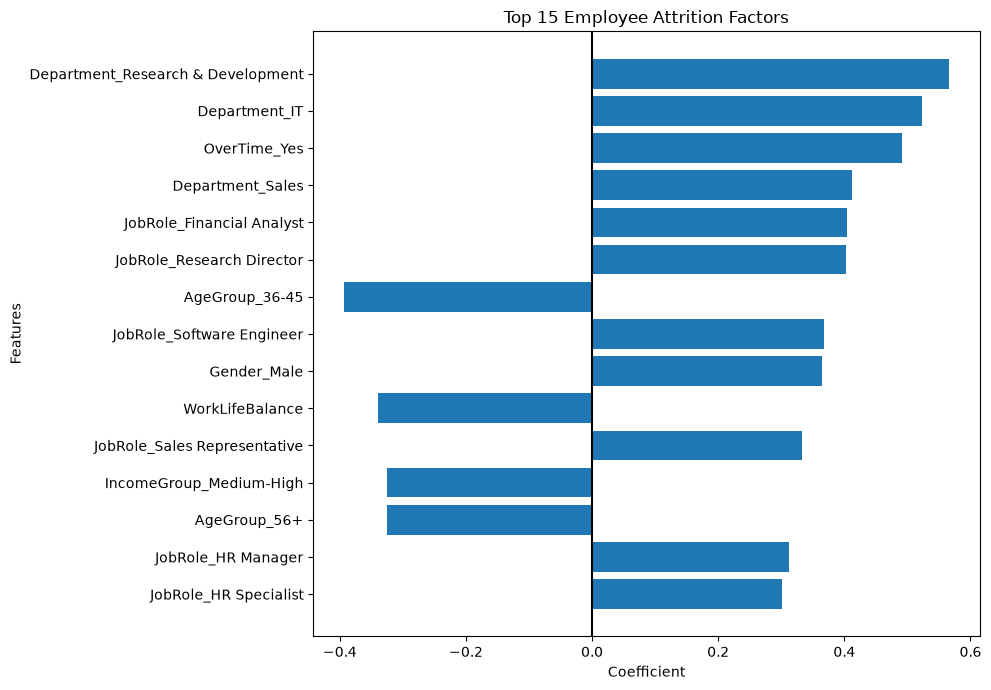

In [75]:
import matplotlib.pyplot as plt

top_features = coefficients.sort_values(
    by='Absolute_Impact',
    ascending=True
).tail(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.xlabel('Coefficient')
plt.ylabel('Features')
plt.title('Top 15 Employee Attrition Factors')
plt.axvline(x=0, color='black')
plt.tight_layout()
plt.show()

In [76]:
print("Total Employees:", len(X))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Best Model: Logistic Regression")
print("Selected Experimental Threshold: 0.30")
print("Attrition Recall:", recall_score(y_test, y_pred_03))
print("Attrition F1 Score:", f1_score(y_test, y_pred_03))

Total Employees: 600
Training Records: 480
Testing Records: 120
Best Model: Logistic Regression
Selected Experimental Threshold: 0.30
Attrition Recall: 0.85
Attrition F1 Score: 0.35051546391752575


# HR Analytics — Interactive Dashboard

This section creates an interactive dashboard **inside Jupyter Notebook** using the existing cleaned dataset (`df_clean`). It does not overwrite the original analysis or retrain your saved ML model.

> Run the notebook's earlier data-cleaning and feature-engineering cells first. Then run these dashboard cells in order.

In [77]:
# Install dashboard libraries (run once if they are not already installed)
%pip install -q plotly ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [78]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML
import ipywidgets as widgets

# Work on a separate dashboard copy; df_clean remains unchanged
dashboard_df = df_clean.copy()

# Make sure dashboard categories exist
if "AgeGroup" not in dashboard_df.columns:
    dashboard_df["AgeGroup"] = pd.cut(
        dashboard_df["Age"],
        bins=[0, 25, 35, 45, 55, 100],
        labels=["18-25", "26-35", "36-45", "46-55", "56+"]
    )

if "IncomeGroup" not in dashboard_df.columns:
    dashboard_df["IncomeGroup"] = pd.cut(
        dashboard_df["MonthlyIncome"],
        bins=4,
        labels=["Low", "Medium-Low", "Medium-High", "High"]
    )

print("Dashboard data ready:", dashboard_df.shape)
print("Missing values after using the cleaned dataset:", int(dashboard_df.isna().sum().sum()))

Dashboard data ready: (600, 21)
Missing values after using the cleaned dataset: 0


## Dashboard filters and KPI cards

In [79]:
# Interactive filters
department_filter = widgets.SelectMultiple(
    options=sorted(dashboard_df["Department"].dropna().unique()),
    value=tuple(sorted(dashboard_df["Department"].dropna().unique())),
    description="Department",
    layout=widgets.Layout(width="320px", height="110px")
)
gender_filter = widgets.SelectMultiple(
    options=sorted(dashboard_df["Gender"].dropna().unique()),
    value=tuple(sorted(dashboard_df["Gender"].dropna().unique())),
    description="Gender",
    layout=widgets.Layout(width="250px", height="110px")
)
overtime_filter = widgets.SelectMultiple(
    options=sorted(dashboard_df["OverTime"].dropna().unique()),
    value=tuple(sorted(dashboard_df["OverTime"].dropna().unique())),
    description="OverTime",
    layout=widgets.Layout(width="220px", height="110px")
)

output = widgets.Output()

def show_hr_dashboard(departments, genders, overtime_values):
    selected = dashboard_df[
        dashboard_df["Department"].isin(departments)
        & dashboard_df["Gender"].isin(genders)
        & dashboard_df["OverTime"].isin(overtime_values)
    ].copy()

    total = len(selected)
    left = int((selected["Attrition"] == "Yes").sum())
    rate = (left / total * 100) if total else 0
    avg_income = selected["MonthlyIncome"].mean() if total else 0

    with output:
        output.clear_output(wait=True)

        # KPI cards
        cards = f'''
        <div style="display:flex;gap:14px;flex-wrap:wrap;margin:12px 0 22px 0;">
          <div style="background:#14213d;color:white;padding:18px 24px;border-radius:12px;min-width:160px;">
            <div style="font-size:13px;">Total Employees</div><div style="font-size:28px;font-weight:bold;">{total:,}</div>
          </div>
          <div style="background:#1d3557;color:white;padding:18px 24px;border-radius:12px;min-width:160px;">
            <div style="font-size:13px;">Employees Left</div><div style="font-size:28px;font-weight:bold;">{left:,}</div>
          </div>
          <div style="background:#457b9d;color:white;padding:18px 24px;border-radius:12px;min-width:160px;">
            <div style="font-size:13px;">Attrition Rate</div><div style="font-size:28px;font-weight:bold;">{rate:.1f}%</div>
          </div>
          <div style="background:#2a9d8f;color:white;padding:18px 24px;border-radius:12px;min-width:190px;">
            <div style="font-size:13px;">Average Monthly Income</div><div style="font-size:28px;font-weight:bold;">{avg_income:,.0f}</div>
          </div>
        </div>'''
        display(HTML(cards))

        if total == 0:
            print("No employees match the selected filters.")
            return

        # Department attrition rate
        dept = selected.groupby("Department").agg(
            Employees=("EmployeeID", "count"),
            Left=("Attrition", lambda x: (x == "Yes").sum())
        ).reset_index()
        dept["Attrition Rate (%)"] = dept["Left"] / dept["Employees"] * 100
        fig1 = px.bar(
            dept, x="Department", y="Attrition Rate (%)",
            color="Department", text_auto=".1f",
            title="Department-wise Attrition Rate"
        )
        fig1.update_layout(showlegend=False)
        fig1.show()

        # Attrition split
        split = selected["Attrition"].value_counts().rename_axis("Attrition").reset_index(name="Employees")
        px.pie(split, names="Attrition", values="Employees", hole=0.55,
               title="Employee Attrition Split").show()

        # Overtime vs attrition
        overtime = pd.crosstab(selected["OverTime"], selected["Attrition"], normalize="index").mul(100).reset_index()
        overtime_long = overtime.melt(id_vars="OverTime", var_name="Attrition", value_name="Percentage")
        px.bar(
            overtime_long, x="OverTime", y="Percentage", color="Attrition",
            barmode="stack", title="Attrition Percentage by Overtime"
        ).show()

        # Age group attrition
        age = selected.groupby("AgeGroup", observed=False).agg(
            Employees=("EmployeeID", "count"),
            Left=("Attrition", lambda x: (x == "Yes").sum())
        ).reset_index()
        age["Attrition Rate (%)"] = np.where(age["Employees"] > 0, age["Left"] / age["Employees"] * 100, 0)
        px.bar(age, x="AgeGroup", y="Attrition Rate (%)", text_auto=".1f",
               title="Attrition Rate by Age Group").show()

        # Job satisfaction
        satisfaction = selected.groupby("JobSatisfaction").agg(
            Employees=("EmployeeID", "count"),
            Left=("Attrition", lambda x: (x == "Yes").sum())
        ).reset_index()
        satisfaction["Attrition Rate (%)"] = satisfaction["Left"] / satisfaction["Employees"] * 100
        px.bar(satisfaction, x="JobSatisfaction", y="Attrition Rate (%)", text_auto=".1f",
               title="Attrition Rate by Job Satisfaction").show()

        # Income group
        income = selected.groupby("IncomeGroup", observed=False).agg(
            Employees=("EmployeeID", "count"),
            Left=("Attrition", lambda x: (x == "Yes").sum())
        ).reset_index()
        income["Attrition Rate (%)"] = np.where(income["Employees"] > 0, income["Left"] / income["Employees"] * 100, 0)
        px.bar(income, x="IncomeGroup", y="Attrition Rate (%)", text_auto=".1f",
               title="Attrition Rate by Monthly Income Group").show()

        display(selected.head(10))

controls = widgets.VBox([
    widgets.HTML("<h3 style='color:#14213d'>Choose dashboard filters</h3>"),
    widgets.HBox([department_filter, gender_filter, overtime_filter])
])
dashboard = widgets.interactive_output(
    show_hr_dashboard,
    {
        "departments": department_filter,
        "genders": gender_filter,
        "overtime_values": overtime_filter
    }
)
display(controls, output, dashboard)

Output()

Output()

## Dashboard notes

- KPI cards and charts update when you change the Department, Gender, or OverTime filters.
- This dashboard uses the cleaned `df_clean` data already created earlier in this notebook.
- The dataset is synthetic practice data, not real employee records.
- Your saved `hr_attrition_model.pkl` is kept separate and unchanged. We can add a dedicated model-prediction input section after confirming this dashboard runs correctly.

# Machine Learning — Employee Attrition Prediction

This section uses the **already-trained Logistic Regression pipeline** saved as `hr_attrition_model.pkl`. It does not train a new model.

Enter a sample employee profile and click **Predict Attrition**. The notebook recreates the feature engineering and one-hot encoding used during training, then aligns the columns to the saved model's exact feature list.

**Important:** The 0.30 probability threshold was explored in this project notebook. It is an experimental decision threshold, not a universal HR rule. Treat predictions as learning/portfolio outputs, never as the sole basis for employment decisions.

Before running this section, make sure `hr_attrition_model.pkl` is in the same folder as this notebook, or update `MODEL_PATH` below.

In [80]:
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Load the saved model without changing/retraining it
MODEL_PATH = Path("hr_attrition_model.pkl")

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        "hr_attrition_model.pkl was not found in the notebook's current folder. "
        "Copy the file into this folder or set MODEL_PATH to its full path."
    )

attrition_model = joblib.load(MODEL_PATH)

# Confirm the saved model has the expected fitted feature information
model_features = list(attrition_model.feature_names_in_)
print("Saved model loaded successfully.")
print("Model type:", type(attrition_model).__name__)
print("Required input features:", len(model_features))
print("Model classes:", attrition_model.classes_)

Saved model loaded successfully.
Model type: Pipeline
Required input features: 44
Model classes: [0 1]


In [81]:
# Use the same feature engineering boundaries/categories as the training notebook
AGE_BINS = [0, 25, 35, 45, 55, 100]
AGE_LABELS = ["18-25", "26-35", "36-45", "46-55", "56+"]

# The training notebook created IncomeGroup using pd.cut(..., bins=4).
# Recreate those same cut points from the cleaned training data.
_, INCOME_BINS = pd.cut(
    df_clean["MonthlyIncome"],
    bins=4,
    retbins=True
)
INCOME_LABELS = ["Low", "Medium-Low", "Medium-High", "High"]

CATEGORICAL_FEATURES = [
    "Gender", "Department", "JobRole", "Education",
    "OverTime", "BusinessTravel", "PromotionLast5Years",
    "AgeGroup", "IncomeGroup"
]

def prepare_employee_for_model(employee_row):
    """Apply notebook feature engineering and align columns to saved model."""
    model_input = employee_row.copy()

    model_input["AgeGroup"] = pd.cut(
        model_input["Age"],
        bins=AGE_BINS,
        labels=AGE_LABELS
    )

    model_input["IncomeGroup"] = pd.cut(
        model_input["MonthlyIncome"],
        bins=INCOME_BINS,
        labels=INCOME_LABELS,
        include_lowest=True
    )

    model_input = pd.get_dummies(
        model_input,
        columns=CATEGORICAL_FEATURES,
        drop_first=True,
        dtype=int
    )

    # Exact feature order expected by the saved model; absent dummy columns become 0.
    model_input = model_input.reindex(
        columns=model_features,
        fill_value=0
    )

    return model_input

print("Prediction preprocessing is ready.")
print("Age groups and income groups match the training notebook.")
print("Encoded model input will contain", len(model_features), "features.")

Prediction preprocessing is ready.
Age groups and income groups match the training notebook.
Encoded model input will contain 44 features.


## Enter employee details and predict

The dropdown choices come from your HR dataset. Numeric defaults use typical values from the dataset. You can change them to test different employee profiles.

In [82]:
# Build input controls from the categories in your dataset
def category_options(column):
    return sorted(df_clean[column].dropna().astype(str).unique().tolist())

age_input = widgets.IntSlider(
    value=30, min=18, max=65, step=1, description="Age",
    style={"description_width": "initial"}
)
gender_input = widgets.Dropdown(
    options=category_options("Gender"), description="Gender",
    style={"description_width": "initial"}
)
department_input = widgets.Dropdown(
    options=category_options("Department"), description="Department",
    style={"description_width": "initial"}, layout=widgets.Layout(width="350px")
)
jobrole_input = widgets.Dropdown(
    options=category_options("JobRole"), description="Job Role",
    style={"description_width": "initial"}, layout=widgets.Layout(width="350px")
)
education_input = widgets.Dropdown(
    options=category_options("Education"), description="Education",
    style={"description_width": "initial"}
)
income_input = widgets.IntSlider(
    value=int(df_clean["MonthlyIncome"].median()),
    min=int(df_clean["MonthlyIncome"].min()),
    max=int(df_clean["MonthlyIncome"].max()),
    step=100,
    description="Monthly Income",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="350px")
)
years_company_input = widgets.IntSlider(
    value=3, min=0, max=40, description="Years at Company",
    style={"description_width": "initial"}, layout=widgets.Layout(width="350px")
)
years_role_input = widgets.IntSlider(
    value=2, min=0, max=30, description="Years in Role",
    style={"description_width": "initial"}, layout=widgets.Layout(width="350px")
)
satisfaction_input = widgets.IntSlider(
    value=3, min=1, max=4, description="Job Satisfaction",
    style={"description_width": "initial"}
)
worklife_input = widgets.IntSlider(
    value=3, min=1, max=4, description="Work-Life Balance",
    style={"description_width": "initial"}
)
performance_input = widgets.IntSlider(
    value=3, min=1, max=4, description="Performance Rating",
    style={"description_width": "initial"}
)
overtime_input = widgets.Dropdown(
    options=category_options("OverTime"), description="OverTime",
    style={"description_width": "initial"}
)
training_input = widgets.IntSlider(
    value=int(df_clean["TrainingHours"].median()),
    min=0, max=max(100, int(df_clean["TrainingHours"].max())),
    description="Training Hours",
    style={"description_width": "initial"}, layout=widgets.Layout(width="350px")
)
travel_input = widgets.Dropdown(
    options=category_options("BusinessTravel"), description="Business Travel",
    style={"description_width": "initial"}, layout=widgets.Layout(width="350px")
)
promotion_input = widgets.Dropdown(
    options=category_options("PromotionLast5Years"), description="Promotion (last 5 years)",
    style={"description_width": "initial"}, layout=widgets.Layout(width="350px")
)
distance_input = widgets.IntSlider(
    value=int(df_clean["DistanceFromHome"].median()),
    min=0, max=max(50, int(df_clean["DistanceFromHome"].max())),
    description="Distance From Home",
    style={"description_width": "initial"}, layout=widgets.Layout(width="350px")
)
hireyear_input = widgets.IntSlider(
    value=int(df_clean["HireDate"].pipe(pd.to_datetime, errors="coerce").dt.year.median()),
    min=2000, max=2026, description="Hire Year",
    style={"description_width": "initial"}
)

predict_button = widgets.Button(
    description="Predict Attrition",
    button_style="primary",
    icon="check",
    layout=widgets.Layout(width="220px", height="42px")
)
prediction_output = widgets.Output()

def run_attrition_prediction(_):
    with prediction_output:
        clear_output(wait=True)

        # One row with the original predictor fields, plus engineered HireYear.
        employee = pd.DataFrame([{
            "Age": age_input.value,
            "Gender": gender_input.value,
            "Department": department_input.value,
            "JobRole": jobrole_input.value,
            "Education": education_input.value,
            "MonthlyIncome": income_input.value,
            "YearsAtCompany": years_company_input.value,
            "YearsInRole": years_role_input.value,
            "JobSatisfaction": satisfaction_input.value,
            "WorkLifeBalance": worklife_input.value,
            "PerformanceRating": performance_input.value,
            "OverTime": overtime_input.value,
            "TrainingHours": training_input.value,
            "BusinessTravel": travel_input.value,
            "PromotionLast5Years": promotion_input.value,
            "DistanceFromHome": distance_input.value,
            "HireYear": hireyear_input.value
        }])

        try:
            X_employee = prepare_employee_for_model(employee)
            probability = float(attrition_model.predict_proba(X_employee)[0, 1])
            threshold = 0.30
            predicted_class = int(probability >= threshold)
            predicted_label = "Yes — flagged by model" if predicted_class == 1 else "No — not flagged by model"
            color = "#b42318" if predicted_class == 1 else "#067647"

            display(HTML(f'''
            <div style="border:1px solid #e2e8f0;border-radius:14px;padding:20px;margin-top:12px;">
              <h3 style="margin:0 0 10px 0;color:#14213d;">Prediction Result</h3>
              <div style="font-size:34px;font-weight:700;color:{color};">{probability:.1%}</div>
              <div style="font-size:15px;margin:4px 0 12px 0;">Estimated probability of attrition</div>
              <div style="font-size:18px;font-weight:600;color:{color};">{predicted_label}</div>
              <div style="color:#64748b;font-size:12px;margin-top:12px;">
                Experimental threshold: {threshold:.0%}. This is a model estimate, not a certainty.
              </div>
            </div>
            '''))
            print("Model output class:", predicted_class, "(0 = No, 1 = Yes)")
        except Exception as error:
            print("Prediction could not be completed:", error)

predict_button.on_click(run_attrition_prediction)

left_controls = widgets.VBox([
    age_input, gender_input, department_input, jobrole_input,
    education_input, income_input, years_company_input, years_role_input
])
right_controls = widgets.VBox([
    satisfaction_input, worklife_input, performance_input,
    overtime_input, training_input, travel_input,
    promotion_input, distance_input, hireyear_input
])

display(widgets.HTML("<h3 style='color:#14213d'>Employee Profile</h3>"))
display(widgets.HBox([left_controls, right_controls]))
display(predict_button, prediction_output)

HTML(value="<h3 style='color:#14213d'>Employee Profile</h3>")

Button(button_style='primary', description='Predict Attrition', icon='check', layout=Layout(height='42px', wid…

Output()

### How to test the model

1. First run the model-loading and preprocessing cells above.
2. Change one or more employee details in the input form.
3. Click **Predict Attrition**.
4. The output shows the estimated probability and whether it crosses the notebook's experimental 0.30 threshold.

Try changing **OverTime** from No to Yes while keeping the other details the same, then compare the results. This is a simple way to explore how the model responds; it does not prove that overtime causes attrition.